# 2. Preparación de los datos

**Proyecto:** Modelo predictivo de consumo de energía eléctrica residencial en Bogotá (TC1/TC2, SUI).
**Entrada:** `dataset_modelo_v4` (109.345.545 registros, 38 columnas), exportado de BigQuery a Parquet.
**Salida:** `dataset_modelo_prep`, conjunto limpio y listo para el modelado.

| Sección | Contenido |
|---|---|
| 0 | Librerías, parámetros y funciones |
| 1 | Carga de datos y muestra de exploración |
| 2 | Limpieza de registros |
| 3 | Eliminación de columnas |
| 4 | Valores atípicos en las características |
| 5 | Variables de calendario |
| 6 | Línea base y punto de control |
| 7 | Interrelación entre variables |
| 8 | Reducción y agrupación de variables |
| 9 | Conjunto final y exportación |
| 10 | Conclusiones |

## Principios estadísticos del notebook

1. **Ninguna relación se supone.** Toda afirmación sobre la relación entre variables se acompaña de una medida calculada aquí.
   Lo que no se mide se declara como *supuesto* y se lista en la sección 10.
2. **Tamaño del efecto antes que valor p.** Con cientos de miles de registros cualquier diferencia es «significativa»;
   las decisiones se basan en el tamaño del efecto, con convenciones declaradas:

   | Medida | Uso | Pequeño | Mediano | Grande |
   |---|---|---|---|---|
   | ρ de Spearman | numérica–numérica | 0,10 | 0,30 | 0,50 |
   | r rango-biserial (Mann–Whitney) | dos grupos | 0,10 | 0,30 | 0,50 |
   | ε² (Kruskal–Wallis) | k grupos | 0,01 | 0,08 | 0,26 |
   | V de Cramér | categórica–categórica | 0,10 | 0,30 | 0,50 |

3. **Independencia.** Un usuario aparece hasta 48 meses. Las pruebas usan **un registro por usuario** para no violar el supuesto de independencia.
4. **Sin fuga de información en la selección.** Las decisiones que usan el objetivo (`KWH_DIA`) solo emplean registros hasta
   `ANIO_EXPLORACION_MAX` (2023). Esto obliga a que prueba y validación del modelado sean posteriores a 2023.
   La selección final de variables por relevancia predictiva se deja al modelado, dentro del conjunto de entrenamiento.
5. **Umbrales declarados.** Los umbrales (Tukey, baja varianza, redundancia) son convenciones; se reporta la sensibilidad a su valor.

*Referencias de las convenciones (por incorporar a la bibliografía y verificar): Tukey (1977) para los límites de atípicos;
Kuhn y Johnson (2013) para variables de varianza casi nula; Cohen (1988) para tamaños de efecto; Tomczak y Tomczak (2014) para ε².*

## 0. Librerías, parámetros y funciones

In [1]:
import os
import glob
import shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import dask.array as da
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from google.colab import drive

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.4f}'.format)
sns.set_theme(style='whitegrid')

Parámetros. Todo umbral se define aquí.

| Parámetro | Significado |
|---|---|
| `K_TUKEY_DIAS` | Factor del IQR para días facturados (1,5 = límite interior de Tukey) |
| `K_TUKEY_KWH` | Factor del IQR sobre `log(1 + KWH_DIA)` (3 = límite exterior de Tukey) |
| `NZV_RAZON`, `NZV_UNICOS` | Varianza casi nula: razón entre la 1.ª y 2.ª categoría más frecuentes y % de valores únicos |
| `UMBRAL_REDUNDANCIA` | \|ρ\| a partir del cual dos características se consideran redundantes |
| `UMBRAL_V_REDUNDANTE` | V de Cramér a partir de la cual una categórica es redundante con otra |
| `UMBRAL_BENCH_CEROS` | Proporción de línea base en cero que invalida un mes para evaluar la línea base |
| `PREFIJO_MUESTRA` | Prefijo del `NIU_USUARIO` (hash) para muestrear usuarios completos (~1/256) |
| `ANIO_EXPLORACION_MAX` | Último año usado en análisis que involucran el objetivo |

In [2]:
K_TUKEY_DIAS = 1.5
K_TUKEY_KWH = 3.0
NZV_RAZON, NZV_UNICOS = 95 / 5, 10
UMBRAL_REDUNDANCIA = 0.95
UMBRAL_V_REDUNDANTE = 0.5
UMBRAL_BENCH_CEROS = 0.5
PREFIJO_MUESTRA = '00'
ANIO_EXPLORACION_MAX = 2023
SEMILLA = 42

In [3]:
DRIVE_ORIGEN = '/content/drive/MyDrive/Superintendencia/dataset_modelo_v4'
LOCAL_ORIGEN = './dataset_modelo_v4'
LOCAL_CHECKPOINT = './dataset_prep_tmp'
DRIVE_SALIDA = '/content/drive/MyDrive/Superintendencia/dataset_modelo_prep'
DRIVE_FIGURAS = '/content/drive/MyDrive/Superintendencia/Distribución Datos/Preparación'

Funciones de apoyo: archivos y bitácora de registros.

In [4]:
def guardar_figura(fig, nombre):
    os.makedirs(DRIVE_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(DRIVE_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')

def copiar(ruta):
    destino = os.path.join(LOCAL_ORIGEN, os.path.basename(ruta))
    if not os.path.exists(destino):
        shutil.copy2(ruta, destino)

In [5]:
bitacora = []

def registrar(paso, ddf):
    n = len(ddf)
    bitacora.append({'paso': paso, 'registros': n})
    print(f'{paso}: {n:,} registros')

Funciones estadísticas: cuartiles, tamaños de efecto y muestreo de un registro por usuario.

In [6]:
def cuartiles(serie):
    return dask.compute(serie.quantile(0.25), serie.quantile(0.75))

def una_por_usuario(d):
    return d.groupby('NIU_USUARIO', observed=True).sample(1, random_state=SEMILLA)

In [7]:
def comparar_grupos(a, b):
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return pd.Series({'n_a': len(a), 'n_b': len(b), 'mediana_a': np.median(a), 'mediana_b': np.median(b),
                      'p_valor': p, 'r_rango_biserial': 1 - 2 * u / (len(a) * len(b))})

In [ ]:
def kruskal_epsilon(d, grupo, y='KWH_DIA'):
    grupos = [g[y].dropna().values for _, g in d.groupby(grupo, observed=True)]
    grupos = [g for g in grupos if len(g) > 1]
    n = sum(len(g) for g in grupos)
    if len(grupos) < 2:
        return pd.Series({'grupos': len(grupos), 'n': n, 'H': np.nan, 'p_valor': np.nan, 'epsilon2': np.nan})
    h, p = stats.kruskal(*grupos)
    return pd.Series({'grupos': len(grupos), 'n': n, 'H': h, 'p_valor': p, 'epsilon2': h / (n - 1)}) 

In [9]:
def cramer_v(tabla):
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

def spearman_ic(x, y):
    m = x.notna() & y.notna()
    rho, p = stats.spearmanr(x[m], y[m])
    n = m.sum(); se = 1.06 / np.sqrt(n - 3)
    lo, hi = np.tanh(np.arctanh(rho) + np.array([-1.96, 1.96]) * se)
    return pd.Series({'n': n, 'rho': rho, 'ic95_inf': lo, 'ic95_sup': hi, 'p_valor': p})

## 1. Carga de datos y muestra de exploración

In [10]:
drive.mount('/content/drive')
os.makedirs(LOCAL_ORIGEN, exist_ok=True)
archivos = glob.glob(os.path.join(DRIVE_ORIGEN, '*.parquet'))
print(f'Archivos en Drive: {len(archivos)}')

Mounted at /content/drive
Archivos en Drive: 1281


In [11]:
with ThreadPoolExecutor(max_workers=12) as ex:
    list(ex.map(copiar, archivos))
print('Copia local terminada')

Copia local terminada


In [12]:
df = dd.read_parquet(f'{LOCAL_ORIGEN}/*.parquet')
df['TIPO_MEDIDOR'] = df['TIPO_MEDIDOR'].replace({'ElectrÃ³nico': 'Electrónico',
                                                 'ElectromecÃ¡nico': 'Electromecánico'})
registrar('0. Conjunto original (v4)', df)

0. Conjunto original (v4): 109,345,545 registros


### 1.1 Muestra de exploración por usuarios
`NIU_USUARIO` es un hash hexadecimal; seleccionar los usuarios cuyo hash empieza por `PREFIJO_MUESTRA` equivale a un
muestreo pseudoaleatorio de usuarios completos (todos sus meses). Su representatividad se verifica con la distribución por estrato.

In [13]:
muestra_raw = df[df['NIU_USUARIO'].str.startswith(PREFIJO_MUESTRA)].compute()
muestra_raw['ANIO'] = pd.to_datetime(muestra_raw['PERIODO']).dt.year
print(f"Muestra: {len(muestra_raw):,} registros de {muestra_raw['NIU_USUARIO'].nunique():,} usuarios")

Muestra: 425,738 registros de 9,419 usuarios


In [14]:
pob = df['ESTRATO_SECTOR'].value_counts(normalize=True).compute().sort_index()
mue = muestra_raw['ESTRATO_SECTOR'].value_counts(normalize=True).sort_index()
pd.DataFrame({'población': pob, 'muestra': mue, 'diferencia (pp)': (mue - pob) * 100})

,población,muestra,diferencia (pp)
ESTRATO_SECTOR,,,
1,0.0764,0.0722,-0.4189
2,0.3400,0.3422,0.2184
3,0.3563,0.3569,0.0596
4,0.1440,0.1444,0.0399
5,0.0467,0.0471,0.0367
6,0.0365,0.0371,0.0643


## 2. Limpieza de registros
Cada filtro se aplica por separado y se registra cuántos registros elimina.

### 2.1 Población objetivo: nivel de tensión 1 y sin autogeneración
**Criterio:** definición de la población de estudio (usuarios residenciales en nivel de tensión 1 que no autogeneran).
Es una decisión de alcance, no una inferencia de los datos. La prueba siguiente solo documenta si el consumo de los
grupos excluidos difiere del resto.

In [15]:
excluidos = df[(df['NIVEL_TENSION'] != 1) | (df['AUTOGENERADOR'] != 3)]
excluidos = excluidos[['NIU_USUARIO', 'KWH_DIA', 'NIVEL_TENSION', 'AUTOGENERADOR']].compute()
resto = muestra_raw.query('NIVEL_TENSION == 1 and AUTOGENERADOR == 3')

In [16]:
pd.DataFrame({
    'Nivel de tensión 2 vs. resto': comparar_grupos(
        una_por_usuario(excluidos.query('NIVEL_TENSION != 1'))['KWH_DIA'], una_por_usuario(resto)['KWH_DIA']),
    'Autogenerador vs. resto': comparar_grupos(
        una_por_usuario(excluidos.query('AUTOGENERADOR != 3'))['KWH_DIA'], una_por_usuario(resto)['KWH_DIA']),
}).T

,n_a,n_b,mediana_a,mediana_b,p_valor,r_rango_biserial
Nivel de tensión 2 vs. resto,16.0000,"9,419.0000",643.6607,3.4000,0.0000,-0.9999
Autogenerador vs. resto,294.0000,"9,419.0000",7.1667,3.4000,0.0000,-0.4652


In [17]:
df = df[(df['NIVEL_TENSION'] == 1) & (df['AUTOGENERADOR'] == 3)]
registrar('1. Nivel de tensión 1 y sin autogeneración', df)

1. Nivel de tensión 1 y sin autogeneración: 109,339,456 registros


### 2.2 Usuarios sin medidor
**Criterio:** la categoría `Usuario sin medidor` indica que no hay medición; el objetivo exige lectura real medida.

In [18]:
df = df[df['TIPO_MEDIDOR'] != 'Usuario sin medidor']
registrar('2. Con medidor', df)

2. Con medidor: 109,338,704 registros


### 2.3 Días facturados atípicos
**Criterio:** límites de Tukey $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ con $k$ = `K_TUKEY_DIAS`.
Antes de aplicar el filtro se muestra la sensibilidad al valor de $k$.

In [19]:
q1_d, q3_d = cuartiles(df['DIAS_FACTURADOS'])
iqr_d = q3_d - q1_d
lim_dias = {k: (q1_d - k * iqr_d, q3_d + k * iqr_d) for k in [1.5, 2.0, 3.0]}
fuera = dask.compute(*[(~df['DIAS_FACTURADOS'].between(lo, hi)).sum() for lo, hi in lim_dias.values()])

In [20]:
pd.DataFrame({'mínimo': [v[0] for v in lim_dias.values()], 'máximo': [v[1] for v in lim_dias.values()],
              'registros fuera': fuera}, index=pd.Index(lim_dias.keys(), name='k'))

,mínimo,máximo,registros fuera
k,,,
1.5000,29.0000,37.0000,11546824
2.0000,28.0000,38.0000,788120
3.0000,26.0000,40.0000,52869


In [21]:
DIAS_MIN, DIAS_MAX = q1_d - K_TUKEY_DIAS * iqr_d, q3_d + K_TUKEY_DIAS * iqr_d
df = df[df['DIAS_FACTURADOS'].between(DIAS_MIN, DIAS_MAX)]
registrar(f'3. Días facturados en [{DIAS_MIN:.1f}, {DIAS_MAX:.1f}]', df)

3. Días facturados en [29.0, 37.0]: 97,791,880 registros


### 2.4 Consumo diario atípico en el objetivo
**Criterio:** límite superior de Tukey sobre $\log(1 + \text{KWH\_DIA})$ con $k$ = `K_TUKEY_KWH`.
Se usa la escala logarítmica porque la distribución tiene asimetría positiva (calidad de datos: Q1 = 2,52; mediana = 4,07;
Q3 = 6,28; máximo = 39.427 kWh/día) y los límites de Tukey suponen una distribución aproximadamente simétrica.
No se aplica límite inferior: los ceros son lecturas reales.

In [22]:
q1_k, q3_k = cuartiles(np.log1p(df['KWH_DIA']))
lim_kwh = {k: np.expm1(q3_k + k * (q3_k - q1_k)) for k in [1.5, 2.0, 3.0]}
fuera = dask.compute(*[(df['KWH_DIA'] > v).sum() for v in lim_kwh.values()])
pd.DataFrame({'límite (kWh/día)': lim_kwh.values(), 'registros fuera': fuera},
             index=pd.Index(lim_kwh.keys(), name='k'))

,límite (kWh/día),registros fuera
k,,
1.5000,21.0049,956144
2.0000,30.8728,471654
3.0000,65.8681,155194


In [23]:
conteo, bordes = da.histogram(np.log1p(df['KWH_DIA'].to_dask_array()), bins=80, range=(0, 11))
conteo = conteo.compute()
UMBRAL_KWH_DIA = np.expm1(q3_k + K_TUKEY_KWH * (q3_k - q1_k))

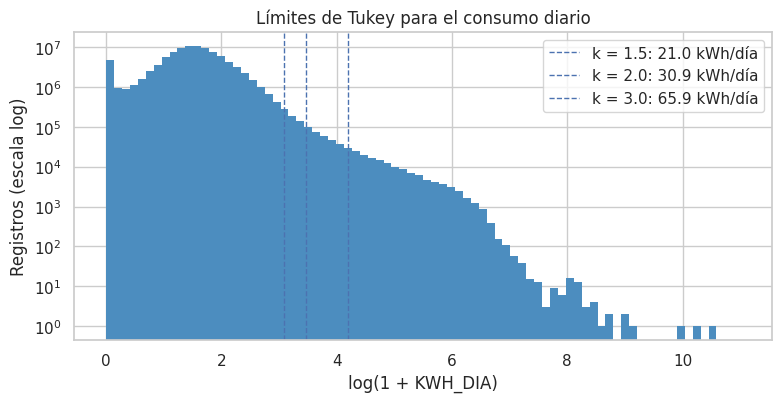

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.stairs(conteo, bordes, fill=True, color='#4C8DBF')
for k, v in lim_kwh.items():
    ax.axvline(np.log1p(v), ls='--', lw=1, label=f'k = {k}: {v:.1f} kWh/día')
ax.set_yscale('log'); ax.set_xlabel('log(1 + KWH_DIA)'); ax.set_ylabel('Registros (escala log)')
ax.set_title('Límites de Tukey para el consumo diario'); ax.legend()
guardar_figura(fig, '01_limites_tukey_kwh')
plt.show()

In [25]:
df = df[df['KWH_DIA'] <= UMBRAL_KWH_DIA]
registrar(f'4. KWH_DIA <= {UMBRAL_KWH_DIA:.1f}', df)

4. KWH_DIA <= 65.9: 97,636,686 registros


### 2.5 Resumen de la limpieza de registros

In [26]:
tabla_limpieza = pd.DataFrame(bitacora)
tabla_limpieza['eliminados'] = -tabla_limpieza['registros'].diff().fillna(0).astype(int)
tabla_limpieza['% conservado'] = tabla_limpieza['registros'] / tabla_limpieza['registros'].iloc[0] * 100
tabla_limpieza

,paso,registros,eliminados,% conservado
0,0. Conjunto original (v4),109345545,0,100.0000
1,1. Nivel de tensión 1 y sin autogeneración,109339456,6089,99.9944
2,2. Con medidor,109338704,752,99.9937
3,"3. Días facturados en [29.0, 37.0]",97791880,11546824,89.4338
4,4. KWH_DIA <= 65.9,97636686,155194,89.2919


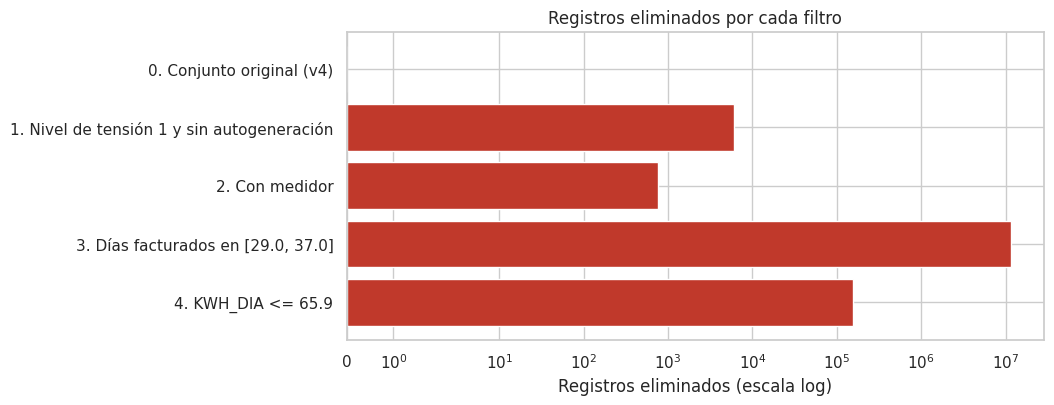

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabla_limpieza['paso'][::-1], tabla_limpieza['eliminados'][::-1], color='#C0392B')
ax.set_xscale('symlog'); ax.set_xlabel('Registros eliminados (escala log)')
ax.set_title('Registros eliminados por cada filtro')
guardar_figura(fig, '02_registros_eliminados')
plt.show()

## 3. Eliminación de columnas

### 3.1 Varianza nula o casi nula
**Criterio (Kuhn y Johnson):** una variable tiene varianza casi nula si la razón entre su categoría más frecuente y la
segunda supera `NZV_RAZON` (19) y sus valores únicos son menos del `NZV_UNICOS` % de los registros.
- Varianza **nula** (un solo valor): se elimina.
- Varianza **casi nula**: no se elimina solo por eso; se mide su relación con el objetivo (sección 3.2).

In [28]:
cols_discretas = ['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR', 'UBICACION',
                  'NRO_FAMILIAS', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR', 'TIPO_MEDIDOR', 'ESTRATO_SECTOR']
conteos = dict(zip(cols_discretas, dask.compute(*[df[c].value_counts() for c in cols_discretas])))
n_actual = bitacora[-1]['registros']

In [29]:
def indicadores_nzv(s):
    s = s.sort_values(ascending=False)
    razon = s.iloc[0] / s.iloc[1] if len(s) > 1 else np.inf
    return pd.Series({'valores': len(s), '% dominante': s.iloc[0] / s.sum() * 100,
                      'razón 1.ª/2.ª': razon, '% únicos': len(s) / n_actual * 100})

tabla_nzv = pd.DataFrame({c: indicadores_nzv(s) for c, s in conteos.items()}).T
tabla_nzv['varianza'] = np.select([tabla_nzv['valores'] == 1,
                                   (tabla_nzv['razón 1.ª/2.ª'] > NZV_RAZON) & (tabla_nzv['% únicos'] < NZV_UNICOS)],
                                  ['nula', 'casi nula'], 'suficiente')
tabla_nzv

,valores,% dominante,razón 1.ª/2.ª,% únicos,varianza
ID_MERCADO,1.0000,100.0000,inf,0.0000,nula
DANE_NIU,1.0000,100.0000,inf,0.0000,nula
TIPO_CONEXION,1.0000,100.0000,inf,0.0000,nula
NIVEL_TENSION,1.0000,100.0000,inf,0.0000,nula
AUTOGENERADOR,1.0000,100.0000,inf,0.0000,nula
UBICACION,3.0000,99.3491,159.4780,0.0000,casi nula
NRO_FAMILIAS,10.0000,99.9988,"247,189.2628",0.0000,casi nula
CAMBIO_TRAFO,2.0000,99.9245,"1,322.9232",0.0000,casi nula
CAMBIO_ESTRATO,2.0000,99.9854,"6,861.2917",0.0000,casi nula
CAMBIO_MEDIDOR,2.0000,97.0515,32.9151,0.0000,casi nula


In [30]:
cols_varianza_nula = tabla_nzv.index[tabla_nzv['varianza'] == 'nula'].tolist()
cols_casi_nula = tabla_nzv.index[tabla_nzv['varianza'] == 'casi nula'].tolist()
print('Varianza nula (se eliminan):', cols_varianza_nula)
print('Varianza casi nula (se evalúan):', cols_casi_nula)

Varianza nula (se eliminan): ['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR']
Varianza casi nula (se evalúan): ['UBICACION', 'NRO_FAMILIAS', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR']


### 3.2 Relación con el objetivo de las variables de varianza casi nula
Se mide el tamaño del efecto (ε² de Kruskal–Wallis) sobre la muestra de exploración, con los mismos filtros de la sección 2: un registro por usuario, años ≤ `ANIO_EXPLORACION_MAX`.
**Criterio:** se eliminan si ε² < 0,01 (efecto menor que pequeño). Si el efecto es mayor, se conservan aunque su varianza sea baja.

In [31]:
filtros_seccion_2 = ('NIVEL_TENSION == 1 and AUTOGENERADOR == 3 and TIPO_MEDIDOR != "Usuario sin medidor"'
                     ' and @DIAS_MIN <= DIAS_FACTURADOS <= @DIAS_MAX and KWH_DIA <= @UMBRAL_KWH_DIA')
exploracion = muestra_raw.query(filtros_seccion_2).query('ANIO <= @ANIO_EXPLORACION_MAX')
exploracion = una_por_usuario(exploracion)
print(f'Registros de exploración (uno por usuario): {len(exploracion):,}')

Registros de exploración (uno por usuario): 8,877


In [35]:
def kruskal_epsilon(d, grupo, y='KWH_DIA'):
    grupos = [g[y].dropna().values for _, g in d.groupby(grupo, observed=True)]
    grupos = [g for g in grupos if len(g) > 1]
    n = sum(len(g) for g in grupos)
    if len(grupos) < 2:
        return pd.Series({'grupos': len(grupos), 'n': n, 'H': np.nan, 'p_valor': np.nan, 'epsilon2': np.nan})
    h, p = stats.kruskal(*grupos)
    return pd.Series({'grupos': len(grupos), 'n': n, 'H': h, 'p_valor': p, 'epsilon2': h / (n - 1)})

efecto_nzv = pd.DataFrame({c: kruskal_epsilon(exploracion, c) for c in cols_casi_nula
                           if exploracion[c].nunique() > 1}).T
display(efecto_nzv)

,grupos,n,H,p_valor,epsilon2
UBICACION,2.0000,"8,876.0000",11.4068,0.0007,0.0013
CAMBIO_TRAFO,2.0000,"8,877.0000",5.3237,0.0210,0.0006
CAMBIO_ESTRATO,1.0000,"8,876.0000",NaN,NaN,NaN
CAMBIO_MEDIDOR,2.0000,"8,877.0000",0.3589,0.5491,0.0000


In [36]:
no_estimable = efecto_nzv.index[efecto_nzv['epsilon2'].isna()].tolist()
cols_nzv_sin_efecto = efecto_nzv.index[efecto_nzv['epsilon2'] < 0.01].tolist() + no_estimable
cols_nzv_sin_efecto += [c for c in cols_casi_nula if c not in efecto_nzv.index]
print('Efecto no estimable (menos de 2 grupos con n > 1):', no_estimable)
print('Casi nula y sin efecto (se eliminan):', cols_nzv_sin_efecto)

Efecto no estimable (menos de 2 grupos con n > 1): ['CAMBIO_ESTRATO']
Casi nula y sin efecto (se eliminan): ['UBICACION', 'CAMBIO_TRAFO', 'CAMBIO_MEDIDOR', 'CAMBIO_ESTRATO', 'NRO_FAMILIAS']


### 3.3 `CONS_SUBSIST` frente al estrato
**Criterio:** si la V de Cramér entre `CONS_SUBSIST` y `ESTRATO_SECTOR` es ≥ `UMBRAL_V_REDUNDANTE`, la primera es redundante.
Además se mide si los registros cuya etiqueta no coincide con su estrato tienen un consumo distinto.

In [37]:
tabla_subsist = df.groupby(['ESTRATO_SECTOR', 'CONS_SUBSIST']).size().compute().unstack(fill_value=0)
tabla_subsist.columns = [c[:40] for c in tabla_subsist.columns]
print(f'V de Cramér: {cramer_v(tabla_subsist):.3f}')
tabla_subsist

V de Cramér: 0.681


,130 kWh mes para alturas iguales o super,173 kWh mes para alturas inferiores a 1.,Cuando se refiera a usuarios de estratos
ESTRATO_SECTOR,,,
1,7306276,221,86068
2,32878108,1192,478848
3,34053540,1933,712004
4,10719,4,14096596
5,4,1,4489417
6,32,51,3521672


In [38]:
e13 = exploracion[exploracion['ESTRATO_SECTOR'] <= 3]
etiqueta_456 = e13['CONS_SUBSIST'].str.startswith('Cuando se refiera')
comparar_grupos(e13.loc[etiqueta_456, 'KWH_DIA'], e13.loc[~etiqueta_456, 'KWH_DIA']).to_frame(
    'Estratos 1–3: etiqueta «4, 5, 6» (a) vs. otras (b)')

,"Estratos 1–3: etiqueta «4, 5, 6» (a) vs. otras (b)"
n_a,49.0000
n_b,"6,812.0000"
mediana_a,2.6000
mediana_b,3.5517
p_valor,0.0036
r_rango_biserial,0.2407


**Decisión:** se elimina si V ≥ `UMBRAL_V_REDUNDANTE`. Si el efecto de la etiqueta inconsistente sobre el consumo es al menos
pequeño (|r| ≥ 0,1), la inconsistencia se reporta como hallazgo de calidad para revisarla con el comercializador.

In [39]:
cols_redundantes = ['CONS_SUBSIST'] if cramer_v(tabla_subsist) >= UMBRAL_V_REDUNDANTE else []
cols_redundantes

['CONS_SUBSIST']

### 3.4 Variables con fuga de información
**Criterio (por definición, no por datos):**
- `CONSUMO_KWH`: el objetivo se calcula como `CONSUMO_KWH / DIAS_FACTURADOS`.
- `ENE_EXPORT`, `CONS_RECUP`, `DIAS_MORA`: se reportan en la misma factura del periodo que se quiere predecir,
  por lo que no están disponibles antes de la lectura.

In [40]:
cols_fuga = ['CONSUMO_KWH', 'ENE_EXPORT', 'CONS_RECUP', 'DIAS_MORA']

### 3.5 Estabilidad de `TIPO_MEDIDOR`
`CAMBIO_MEDIDOR` y `MESES_DESDE_CAMBIO` dependen de que `TIPO_MEDIDOR` cambie solo cuando se cambia el medidor.
**Prueba:** en la muestra de usuarios (todos los años, sin usar el objetivo) se cuentan los cambios entre registros consecutivos
y cuántos de ellos se revierten en el registro siguiente (patrón A → B → A).
**Criterio:** si más del 50 % de los cambios se revierten, la variable no mide cambios físicos y ambas columnas se eliminan.

In [41]:
serie = muestra_raw.sort_values(['NIU_USUARIO', 'PERIODO'])
g = serie.groupby('NIU_USUARIO')['TIPO_MEDIDOR']
ant1, ant2 = g.shift(1), g.shift(2)
cambio = ant1.notna() & (serie['TIPO_MEDIDOR'] != ant1)
reversion = cambio.shift(1, fill_value=False) & (serie['TIPO_MEDIDOR'] == ant2) & (serie['TIPO_MEDIDOR'] != ant1)

In [42]:
n_cambios, n_rev = int(cambio.sum()), int(reversion.sum())
pd.Series({'% registros con cambio': cambio.mean() * 100, 'cambios': n_cambios,
           'reversiones A→B→A': n_rev, '% de cambios revertidos': n_rev / max(n_cambios, 1) * 100})

,0
% registros con cambio,2.1748
cambios,"9,259.0000"
reversiones A→B→A,14.0000
% de cambios revertidos,0.1512


In [43]:
cols_no_confiables = ['CAMBIO_MEDIDOR', 'MESES_DESDE_CAMBIO'] if n_rev / max(n_cambios, 1) > 0.5 else []
cols_no_confiables

[]

### 3.6 Resumen y eliminación

In [44]:
grupos = {'Varianza nula': cols_varianza_nula, 'Varianza casi nula sin efecto': cols_nzv_sin_efecto,
          'Redundante': cols_redundantes, 'Fuga de información': cols_fuga, 'No confiable': cols_no_confiables}
resumen_cols = pd.DataFrame([(m, c) for m, cs in grupos.items() for c in cs], columns=['motivo', 'columna'])
resumen_cols = resumen_cols.drop_duplicates('columna')
resumen_cols

,motivo,columna
0,Varianza nula,ID_MERCADO
1,Varianza nula,DANE_NIU
2,Varianza nula,TIPO_CONEXION
3,Varianza nula,NIVEL_TENSION
4,Varianza nula,AUTOGENERADOR
5,Varianza casi nula sin efecto,UBICACION
6,Varianza casi nula sin efecto,CAMBIO_TRAFO
7,Varianza casi nula sin efecto,CAMBIO_MEDIDOR
8,Varianza casi nula sin efecto,CAMBIO_ESTRATO
9,Varianza casi nula sin efecto,NRO_FAMILIAS


In [45]:
df = df.drop(columns=resumen_cols['columna'].tolist())
print(f'Columnas restantes ({len(df.columns)}):', list(df.columns))

Columnas restantes (23): ['PERIODO', 'MES', 'NIU_USUARIO', 'COD_CIRCUITO_LINEA', 'COD_TRANSFORMADOR', 'ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'DIAS_FACTURADOS', 'PROM_SEM_BENCHMARK', 'FECHA_LECTURA', 'FECHA_FACTURA', 'KWH_DIA', 'KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12', 'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_STD6', 'KWH_DIA_MM12', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'MESES_DESDE_CAMBIO']


## 4. Valores atípicos en las características
Los rezagos y medias móviles se calcularon en BigQuery antes del filtro de lectura real (*004.6 Consulta dataset_modelo_v4*).
**Criterio:** se aplica el mismo límite del objetivo (`UMBRAL_KWH_DIA`, sección 2.4), porque son la misma magnitud
(kWh/día) en meses anteriores. Los valores que lo superan pasan a nulo (no se elimina el registro, porque su objetivo es válido).

In [46]:
cols_consumo = ['KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
                'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_MM12']
n_extremos = dask.compute(*[(df[c] > UMBRAL_KWH_DIA).sum() for c in cols_consumo])
pd.Series(n_extremos, index=cols_consumo, name='valores > umbral')

,valores > umbral
KWH_DIA_LAG1,14876
KWH_DIA_LAG2,15303
KWH_DIA_LAG3,16409
KWH_DIA_LAG12,17884
KWH_DIA_MM3,12912
KWH_DIA_MM6,12773
KWH_DIA_MM12,13368


In [47]:
for c in cols_consumo:
    df[c] = df[c].where(df[c] <= UMBRAL_KWH_DIA)
df['KWH_DIA_STD6'] = df['KWH_DIA_STD6'].where(df['KWH_DIA_MM6'].notnull())

## 5. Variables de calendario
`PERIODO` es el mes de **reporte**. Por definición de los campos de TC2, el consumo facturado corresponde a los
`DIAS_FACTURADOS` anteriores a `FECHA_LECTURA`.

**Supuesto (no verificable con estos datos):** la fecha real de lectura se usa como aproximación de la fecha planeada
del cronograma de lectura, que sí se conoce antes de leer. Debe validarse con el comercializador.
`FECHA_FACTURA` es posterior a la lectura; solo se usa para calcular el retraso de facturación.

In [48]:
df['F_LECTURA'] = dd.to_datetime(df['FECHA_LECTURA'], format='%d/%m/%y', errors='coerce')
df['F_FACTURA'] = dd.to_datetime(df['FECHA_FACTURA'], format='%d/%m/%y', errors='coerce')

### 5.1 Validación de las fechas

In [49]:
chequeos = dask.compute(df['F_LECTURA'].isnull().mean(), df['F_FACTURA'].isnull().mean(),
                        (df['F_FACTURA'] < df['F_LECTURA']).mean(),
                        df['F_LECTURA'].min(), df['F_LECTURA'].max())
pd.Series(chequeos, index=['% lectura no convertible', '% factura no convertible',
                           '% factura antes de lectura', 'lectura mínima', 'lectura máxima'])

,0
% lectura no convertible,0.0000
% factura no convertible,0.0000
% factura antes de lectura,0.0000
lectura mínima,2021-12-28 00:00:00
lectura máxima,2025-12-31 00:00:00


### 5.2 Variables derivadas
| Variable | Definición |
|---|---|
| `DIA_LECTURA` | Día del mes de `FECHA_LECTURA` |
| `MES_CONSUMO` | Mes de `FECHA_LECTURA − DIAS_FACTURADOS / 2` (punto medio de la ventana) |
| `DIAS_FIN_SEMANA` | Sábados y domingos en la ventana `[lectura − días, lectura)` |
| `DIAS_FESTIVOS` | Festivos de Colombia en días hábiles de la ventana (librería `holidays`) |
| `RETRASO_FACTURA` | `FECHA_FACTURA − FECHA_LECTURA`, en días |

In [50]:
df['DIA_LECTURA'] = df['F_LECTURA'].dt.day
medio = df['F_LECTURA'] - dd.to_timedelta(df['DIAS_FACTURADOS'] / 2, unit='D')
df['MES_CONSUMO'] = medio.dt.month
df['RETRASO_FACTURA'] = (df['F_FACTURA'] - df['F_LECTURA']).dt.days

In [51]:
FESTIVOS = np.array(sorted(holidays.Colombia(years=range(2021, 2026))), dtype='datetime64[D]')

def contar_dias(p):
    fin = p['F_LECTURA'].values.astype('datetime64[D]')
    ini = fin - p['DIAS_FACTURADOS'].values.astype('timedelta64[D]')
    ok = ~np.isnat(fin)
    lab = np.full(len(p), np.nan); hab = np.full(len(p), np.nan)
    lab[ok] = np.busday_count(ini[ok], fin[ok])
    hab[ok] = np.busday_count(ini[ok], fin[ok], holidays=FESTIVOS)
    return p.assign(DIAS_FIN_SEMANA=p['DIAS_FACTURADOS'] - lab, DIAS_FESTIVOS=lab - hab)

In [52]:
meta = df._meta.assign(DIAS_FIN_SEMANA=np.float64(), DIAS_FESTIVOS=np.float64())
df = df.map_partitions(contar_dias, meta=meta)
df = df.drop(columns=['FECHA_LECTURA', 'FECHA_FACTURA', 'F_LECTURA', 'F_FACTURA'])
cols_calendario = ['DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA']

## 6. Línea base y punto de control

### 6.1 Meses con línea base inválida
**Criterio:** un mes se marca como inválido para evaluar la línea base si más del `UMBRAL_BENCH_CEROS` de sus registros
tiene `PROM_SEM_BENCHMARK = 0`. El registro se conserva para el entrenamiento, porque su objetivo es válido.

In [53]:
periodo_txt = df['PERIODO'].astype(str)
ceros_mes = (df['PROM_SEM_BENCHMARK'] == 0).groupby(periodo_txt).mean().compute().sort_index()
PERIODOS_BENCH_INVALIDOS = ceros_mes[ceros_mes > UMBRAL_BENCH_CEROS].index.tolist()
print('Meses inválidos:', PERIODOS_BENCH_INVALIDOS)

Meses inválidos: ['2023-09-01']


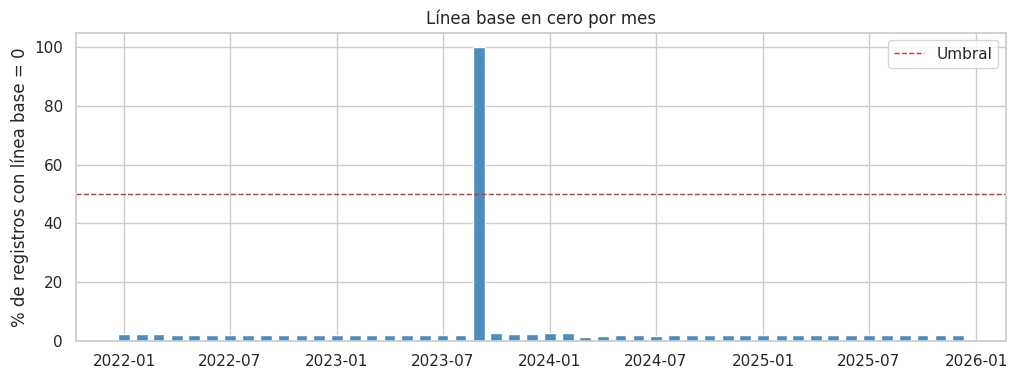

In [54]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(pd.to_datetime(ceros_mes.index), ceros_mes.values * 100, width=20, color='#4C8DBF')
ax.axhline(UMBRAL_BENCH_CEROS * 100, color='#C0392B', ls='--', lw=1, label='Umbral')
ax.set_ylabel('% de registros con línea base = 0'); ax.set_title('Línea base en cero por mes')
ax.legend()
guardar_figura(fig, '03_linea_base_ceros')
plt.show()

In [55]:
df['BENCH_KWH_DIA'] = df['PROM_SEM_BENCHMARK'] / df['DIAS_FACTURADOS']
df['BENCH_VALIDO'] = (~periodo_txt.isin(PERIODOS_BENCH_INVALIDOS)).astype('int8')

### 6.2 Punto de control
Dask acumula las operaciones sin ejecutarlas. Se guarda el resultado en disco local y se vuelve a leer para que las
secciones siguientes no repitan toda la preparación (en la primera ejecución, tomar la muestra sin este paso agotó la conexión con Colab).

In [56]:
df.to_parquet(LOCAL_CHECKPOINT, write_index=False, overwrite=True)
df = dd.read_parquet(LOCAL_CHECKPOINT)
registrar('5. Punto de control', df)
df.dtypes

5. Punto de control: 97,636,686 registros


,0
PERIODO,date32[day][pyarrow]
MES,float64
NIU_USUARIO,string[pyarrow]
COD_CIRCUITO_LINEA,string[pyarrow]
COD_TRANSFORMADOR,string[pyarrow]
ESTRATO_SECTOR,float64
TIPO_MEDIDOR,string[pyarrow]
DIAS_FACTURADOS,float64
PROM_SEM_BENCHMARK,float64
KWH_DIA,float64


## 7. Interrelación entre variables
Se usan los mismos usuarios de la muestra de exploración, ya preparados, con años ≤ `ANIO_EXPLORACION_MAX`.
- `muestra`: todos los meses de esos usuarios (gráficas descriptivas).
- `indep`: un registro por usuario (medidas de asociación e intervalos de confianza).

In [57]:
anio = dd.to_datetime(df['PERIODO']).dt.year
muestra = df[df['NIU_USUARIO'].str.startswith(PREFIJO_MUESTRA) & (anio <= ANIO_EXPLORACION_MAX)].compute()
indep = una_por_usuario(muestra)
print(f'muestra: {len(muestra):,} registros | indep: {len(indep):,} usuarios')

muestra: 179,248 registros | indep: 8,877 usuarios


### 7.1 Correlación de Spearman entre variables numéricas (un registro por usuario)

In [58]:
cols_num = ['KWH_DIA', 'BENCH_KWH_DIA'] + cols_consumo + \
           ['KWH_DIA_STD6', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
corr = indep[cols_num].corr(method='spearman')

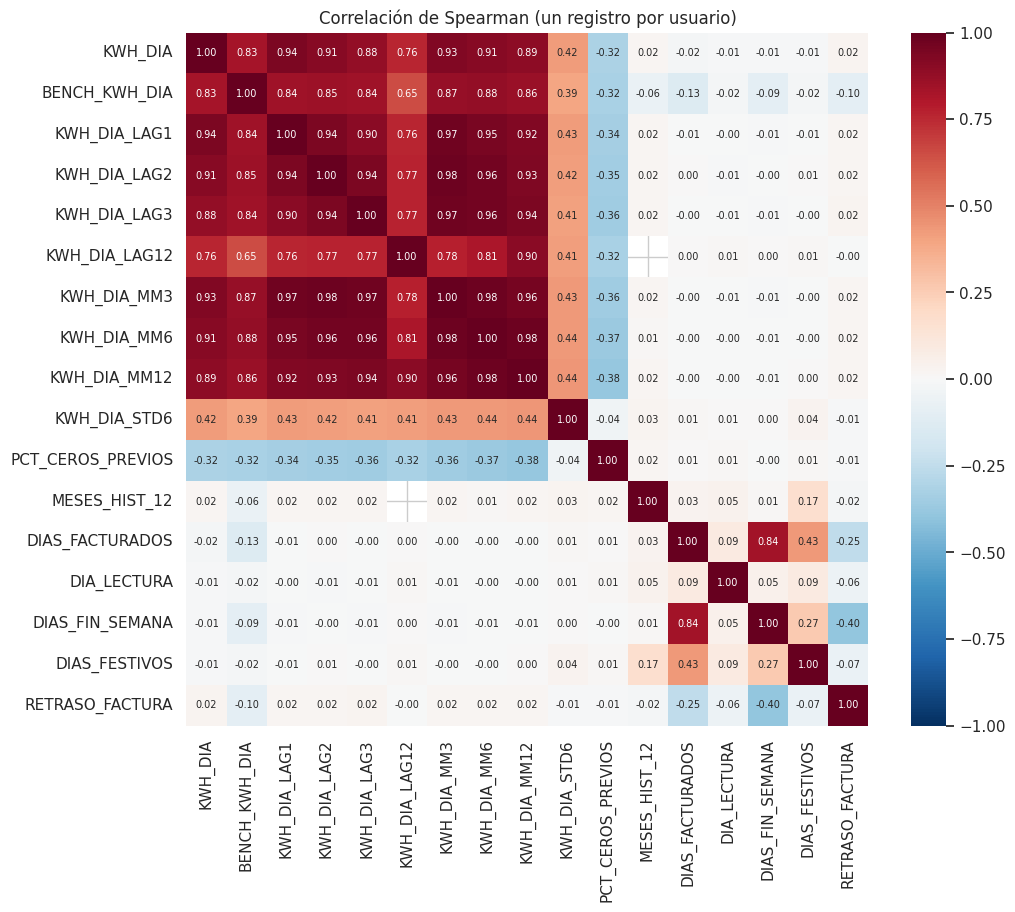

In [59]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlación de Spearman (un registro por usuario)')
guardar_figura(fig, '04_correlacion_spearman')
plt.show()

### 7.2 Asociación de cada variable numérica con el objetivo (ρ e IC 95 %)

In [60]:
asoc_num = pd.DataFrame({c: spearman_ic(indep[c], indep['KWH_DIA']) for c in cols_num if c != 'KWH_DIA'}).T
asoc_num = asoc_num.sort_values('rho')
asoc_num

,n,rho,ic95_inf,ic95_sup,p_valor
PCT_CEROS_PREVIOS,"8,430.0000",-0.3161,-0.3364,-0.2956,0.0000
DIAS_FACTURADOS,"8,877.0000",-0.0178,-0.0398,0.0043,0.0944
DIAS_FIN_SEMANA,"8,877.0000",-0.0143,-0.0363,0.0078,0.1779
DIAS_FESTIVOS,"8,877.0000",-0.0111,-0.0332,0.0109,0.2950
DIA_LECTURA,"8,877.0000",-0.0095,-0.0316,0.0125,0.3684
MESES_HIST_12,"8,877.0000",0.0170,-0.0050,0.0391,0.1088
RETRASO_FACTURA,"8,877.0000",0.0247,0.0027,0.0468,0.0197
KWH_DIA_STD6,"8,251.0000",0.4229,0.4039,0.4415,0.0000
KWH_DIA_LAG12,"4,269.0000",0.7587,0.7448,0.7718,0.0000
BENCH_KWH_DIA,"8,877.0000",0.8321,0.8251,0.8387,0.0000


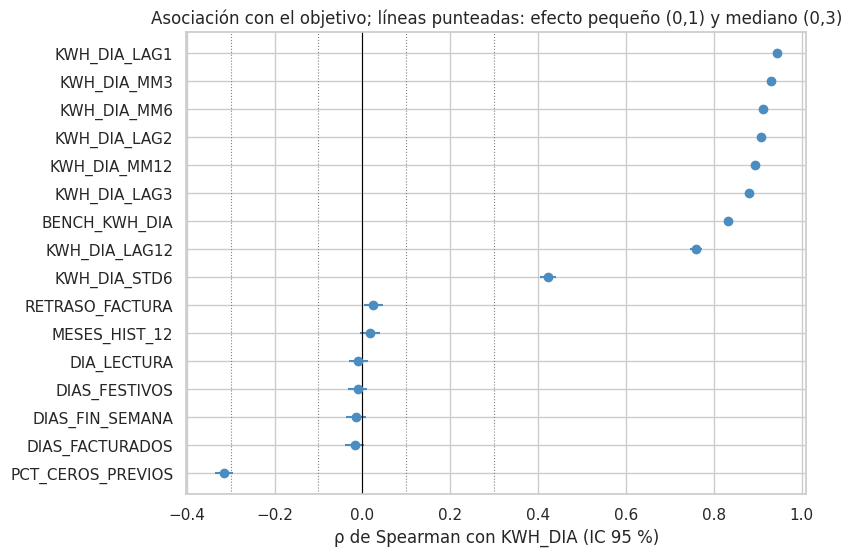

In [61]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(asoc_num['rho'], asoc_num.index, fmt='o', color='#4C8DBF',
            xerr=[asoc_num['rho'] - asoc_num['ic95_inf'], asoc_num['ic95_sup'] - asoc_num['rho']])
for v in [-0.1, 0.1, -0.3, 0.3]:
    ax.axvline(v, color='grey', ls=':', lw=0.8)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('ρ de Spearman con KWH_DIA (IC 95 %)')
ax.set_title('Asociación con el objetivo; líneas punteadas: efecto pequeño (0,1) y mediano (0,3)')
guardar_figura(fig, '05_asociacion_objetivo')
plt.show()

### 7.3 Asociación de las variables categóricas con el objetivo (ε² de Kruskal–Wallis)

In [62]:
cols_cat_eval = ['ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES', 'MES_CONSUMO', 'DIA_LECTURA']
asoc_cat = pd.DataFrame({c: kruskal_epsilon(indep, c) for c in cols_cat_eval}).T
asoc_cat.sort_values('epsilon2', ascending=False)

,grupos,n,H,p_valor,epsilon2
ESTRATO_SECTOR,6.0000,"8,877.0000",101.2209,0.0000,0.0114
TIPO_MEDIDOR,4.0000,"8,877.0000",79.0382,0.0000,0.0089
DIA_LECTURA,31.0000,"8,877.0000",29.6776,0.4823,0.0033
MES,12.0000,"8,877.0000",13.9025,0.2384,0.0016
MES_CONSUMO,12.0000,"8,877.0000",12.1590,0.3518,0.0014


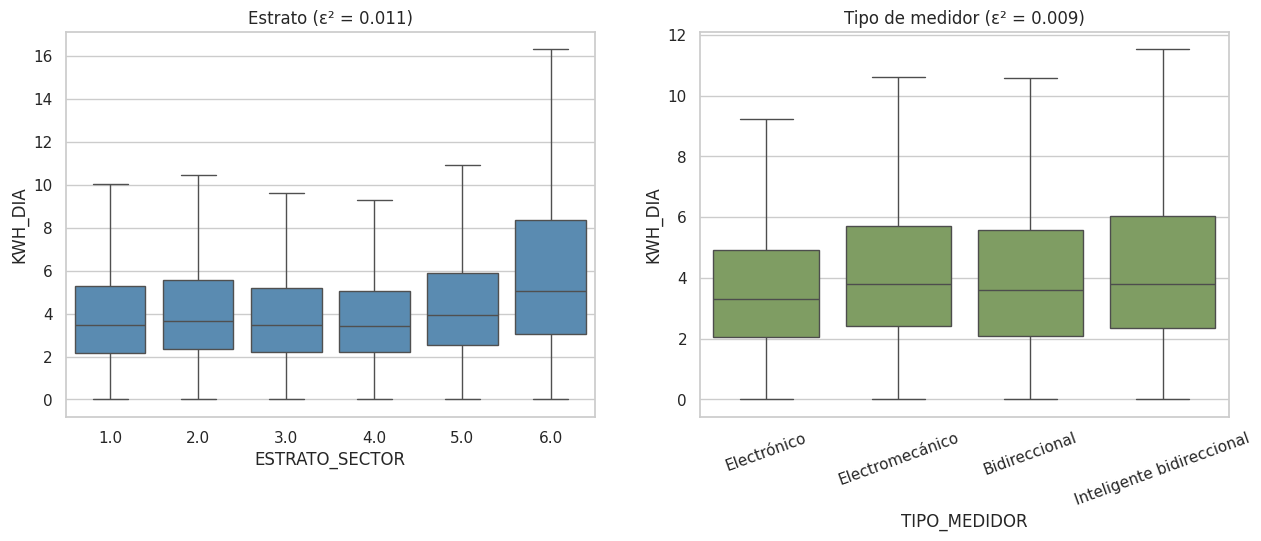

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=muestra, x='ESTRATO_SECTOR', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=axes[0])
sns.boxplot(data=muestra, x='TIPO_MEDIDOR', y='KWH_DIA', showfliers=False, color='#7FA65A', ax=axes[1])
axes[0].set_title(f"Estrato (ε² = {asoc_cat.loc['ESTRATO_SECTOR', 'epsilon2']:.3f})")
axes[1].set_title(f"Tipo de medidor (ε² = {asoc_cat.loc['TIPO_MEDIDOR', 'epsilon2']:.3f})")
axes[1].tick_params(axis='x', rotation=20)
guardar_figura(fig, '06_consumo_estrato_medidor')
plt.show()

### 7.4 Consumo del mes anterior frente al consumo actual

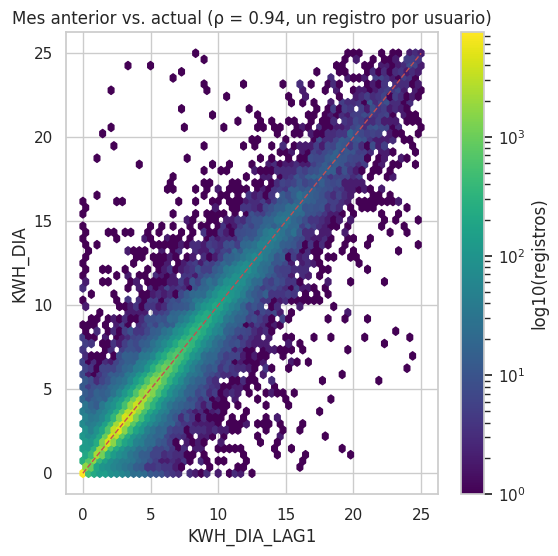

In [64]:
rho_lag1 = asoc_num.loc['KWH_DIA_LAG1', 'rho']
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(muestra['KWH_DIA_LAG1'], muestra['KWH_DIA'], gridsize=60, extent=(0, 25, 0, 25),
               bins='log', cmap='viridis', mincnt=1)
ax.plot([0, 25], [0, 25], 'r--', lw=1)
ax.set_xlabel('KWH_DIA_LAG1'); ax.set_ylabel('KWH_DIA')
ax.set_title(f'Mes anterior vs. actual (ρ = {rho_lag1:.2f}, un registro por usuario)')
fig.colorbar(hb, label='log10(registros)')
guardar_figura(fig, '07_lag1_vs_objetivo')
plt.show()

### 7.5 Perfil mensual del consumo por estrato (descriptivo)

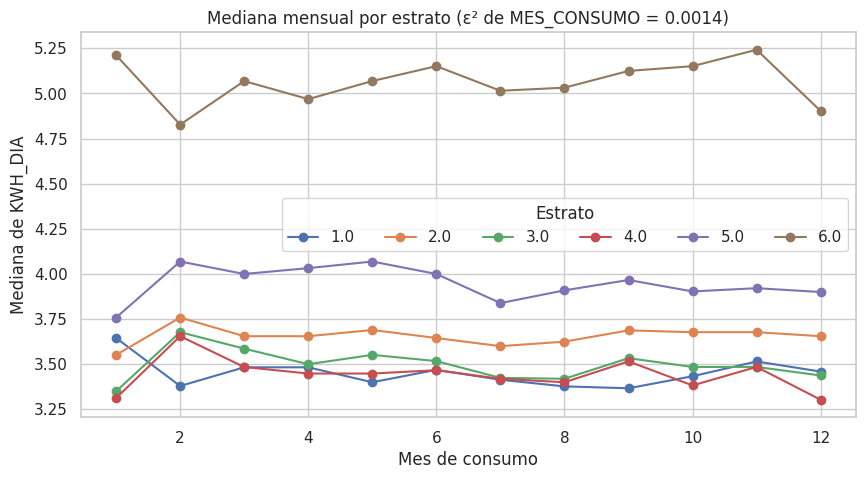

In [65]:
perfil = muestra.groupby(['MES_CONSUMO', 'ESTRATO_SECTOR'])['KWH_DIA'].median().unstack()
fig, ax = plt.subplots(figsize=(10, 5))
perfil.plot(ax=ax, marker='o')
ax.set_xlabel('Mes de consumo'); ax.set_ylabel('Mediana de KWH_DIA')
ax.set_title(f"Mediana mensual por estrato (ε² de MES_CONSUMO = {asoc_cat.loc['MES_CONSUMO', 'epsilon2']:.4f})")
ax.legend(title='Estrato', ncol=6)
guardar_figura(fig, '08_perfil_mensual_estrato')
plt.show()

### 7.6 Meses previos en cero y consumo actual

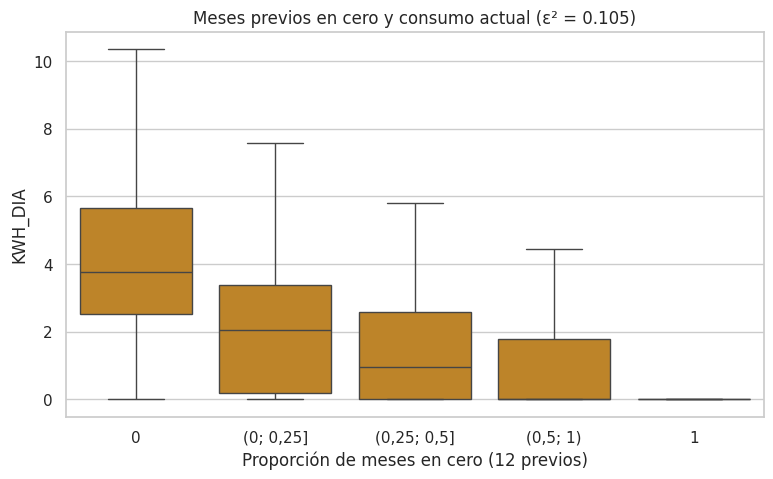

In [67]:
indep = indep.reset_index(drop=True)
indep['GRUPO_CEROS'] = pd.cut(indep['PCT_CEROS_PREVIOS'], [-0.01, 0, 0.25, 0.5, 0.99, 1],
                              labels=['0', '(0; 0,25]', '(0,25; 0,5]', '(0,5; 1)', '1'])
eps_ceros = kruskal_epsilon(indep, 'GRUPO_CEROS')['epsilon2']
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=indep, x='GRUPO_CEROS', y='KWH_DIA', showfliers=False, color='#D68910', ax=ax)
ax.set_xlabel('Proporción de meses en cero (12 previos)'); ax.set_ylabel('KWH_DIA')
ax.set_title(f'Meses previos en cero y consumo actual (ε² = {eps_ceros:.3f})')
guardar_figura(fig, '09_ceros_previos')
plt.show()

In [68]:
muestra = muestra.reset_index(drop=True)
indep = indep.reset_index(drop=True)

### 7.7 Usuarios por transformador (último mes disponible)

In [71]:
periodo_txt = df['PERIODO'].astype(str)
ultimo = periodo_txt.max().compute()
usuarios_trafo = df[periodo_txt == ultimo]['COD_TRANSFORMADOR'].value_counts().compute()
usuarios_trafo.describe()

,count
count,"34,202.0000"
mean,69.6800
std,91.9771
min,1.0000
25%,12.0000
50%,43.0000
75%,100.0000
max,"6,155.0000"


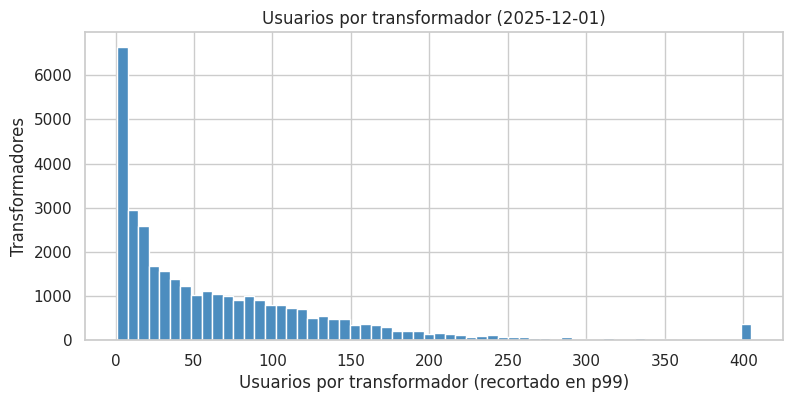

In [72]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(usuarios_trafo.clip(upper=usuarios_trafo.quantile(0.99)), bins=60, color='#4C8DBF')
ax.set_xlabel('Usuarios por transformador (recortado en p99)'); ax.set_ylabel('Transformadores')
ax.set_title(f'Usuarios por transformador ({ultimo})')
guardar_figura(fig, '10_usuarios_transformador')
plt.show()

### 7.8 Variables de calendario

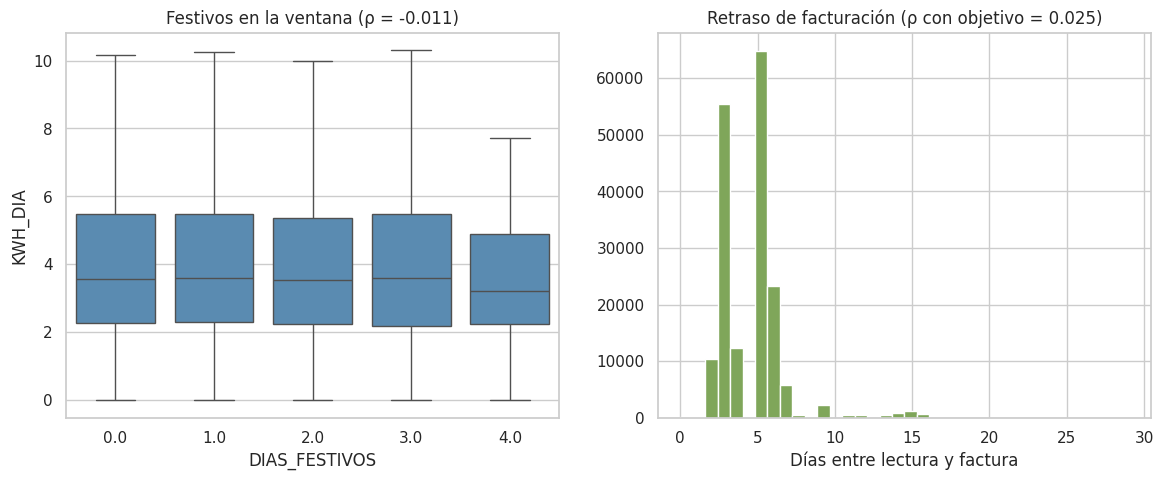

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=indep, x='DIAS_FESTIVOS', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=axes[0])
axes[0].set_title(f"Festivos en la ventana (ρ = {asoc_num.loc['DIAS_FESTIVOS', 'rho']:.3f})")
axes[1].hist(muestra['RETRASO_FACTURA'].clip(-5, 30), bins=36, color='#7FA65A')
axes[1].set_title(f"Retraso de facturación (ρ con objetivo = {asoc_num.loc['RETRASO_FACTURA', 'rho']:.3f})")
axes[1].set_xlabel('Días entre lectura y factura')
guardar_figura(fig, '11_calendario')
plt.show()

## 8. Reducción y agrupación de variables
Esta sección **no usa el objetivo**: la redundancia se mide solo entre características.
La selección por relevancia predictiva se hará en el modelado, dentro del entrenamiento.

### 8.1 Dimensionalidad del bloque de consumo histórico (PCA)

In [74]:
bloque = indep[cols_consumo + ['KWH_DIA_STD6']].dropna()
pca = PCA().fit(StandardScaler().fit_transform(bloque))
var_acum = np.cumsum(pca.explained_variance_ratio_)
pd.DataFrame({'varianza': pca.explained_variance_ratio_, 'acumulada': var_acum},
             index=[f'CP{i + 1}' for i in range(len(var_acum))])

,varianza,acumulada
CP1,0.8604,0.8604
CP2,0.0967,0.9571
CP3,0.0268,0.9839
CP4,0.0085,0.9924
CP5,0.0040,0.9963
CP6,0.0032,0.9995
CP7,0.0005,1.0000
CP8,0.0000,1.0000


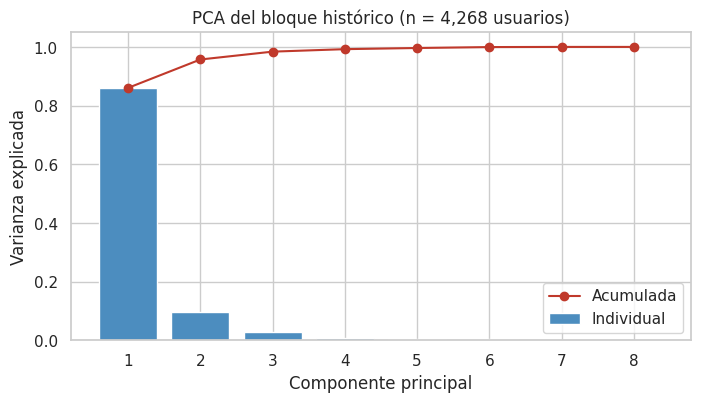

In [75]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(1, len(var_acum) + 1)
ax.bar(x, pca.explained_variance_ratio_, color='#4C8DBF', label='Individual')
ax.plot(x, var_acum, 'o-', color='#C0392B', label='Acumulada')
ax.set_xlabel('Componente principal'); ax.set_ylabel('Varianza explicada')
ax.set_title(f'PCA del bloque histórico (n = {len(bloque):,} usuarios)'); ax.legend()
guardar_figura(fig, '12_pca_consumo')
plt.show()

In [76]:
pd.DataFrame(pca.components_[:3].T, index=bloque.columns, columns=['CP1', 'CP2', 'CP3']).round(3)

,CP1,CP2,CP3
KWH_DIA_LAG1,0.3710,-0.0330,-0.2680
KWH_DIA_LAG2,0.3730,-0.0380,-0.2750
KWH_DIA_LAG3,0.3710,-0.0970,-0.1600
KWH_DIA_LAG12,0.3480,-0.0980,0.8440
KWH_DIA_MM3,0.3780,-0.0570,-0.2390
KWH_DIA_MM6,0.3770,-0.0930,-0.0880
KWH_DIA_MM12,0.3750,-0.0970,0.2180
KWH_DIA_STD6,0.1940,0.9780,0.0480


### 8.2 Variables agrupadas
Transformaciones deterministas del bloque histórico (no se estiman con los datos):

| Variable | Fórmula |
|---|---|
| `NIVEL_12` | `KWH_DIA_MM12` |
| `TENDENCIA` | `KWH_DIA_MM3 − KWH_DIA_MM12` |
| `ESTACIONAL` | `KWH_DIA_LAG12 − KWH_DIA_MM12` |
| `CV6` | `KWH_DIA_STD6 / KWH_DIA_MM6` (si `KWH_DIA_MM6 > 0`) |

In [77]:
def agrupar(d):
    return d.assign(NIVEL_12=d['KWH_DIA_MM12'],
                    TENDENCIA=d['KWH_DIA_MM3'] - d['KWH_DIA_MM12'],
                    ESTACIONAL=d['KWH_DIA_LAG12'] - d['KWH_DIA_MM12'],
                    CV6=(d['KWH_DIA_STD6'] / d['KWH_DIA_MM6']).where(d['KWH_DIA_MM6'] > 0))

df, indep = agrupar(df), agrupar(indep)

### 8.3 Redundancia por agrupamiento jerárquico
**Método:** distancia $1 - |\rho|$ y enlace completo; con corte en $1 -$ `UMBRAL_REDUNDANCIA`, dentro de cada grupo
**todas** las parejas tienen $|\rho| \geq$ `UMBRAL_REDUNDANCIA`.
**Representante de cada grupo:** la variable con menos valores nulos; en empate, la que aparece primero en `candidatas`
(ordenadas de más a menos interpretable). No se usa el objetivo.

In [78]:
candidatas = ['KWH_DIA_LAG1', 'KWH_DIA_LAG12', 'NIVEL_12', 'TENDENCIA', 'ESTACIONAL', 'CV6', 'KWH_DIA_STD6',
              'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'PCT_CEROS_PREVIOS',
              'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
candidatas += [c for c in ['NRO_FAMILIAS', 'MESES_DESDE_CAMBIO'] if c in df.columns]
corr_c = indep[candidatas].corr(method='spearman').abs().fillna(0)
np.fill_diagonal(corr_c.values, 1)
Z = linkage(squareform(1 - corr_c.values, checks=False), method='complete')
grupo = pd.Series(fcluster(Z, t=1 - UMBRAL_REDUNDANCIA, criterion='distance'), index=candidatas)

In [79]:
nulos = indep[candidatas].isnull().mean()
orden = pd.Series(range(len(candidatas)), index=candidatas)
tabla_red = pd.DataFrame({'grupo': grupo, '% nulos': nulos * 100, 'orden': orden})
representantes = tabla_red.sort_values(['% nulos', 'orden']).groupby('grupo').head(1).index
tabla_red['seleccionada'] = tabla_red.index.isin(representantes)
tabla_red.sort_values(['grupo', 'orden'])

,grupo,% nulos,orden,seleccionada
MESES_HIST_12,1,0.0000,12,True
MESES_DESDE_CAMBIO,2,8.2573,18,True
DIAS_FACTURADOS,3,0.0000,13,True
DIAS_FIN_SEMANA,4,0.0000,15,True
DIAS_FESTIVOS,5,0.0000,16,True
RETRASO_FACTURA,6,0.0000,17,True
DIA_LECTURA,7,0.0000,14,True
TENDENCIA,8,5.0805,3,True
ESTACIONAL,9,51.9094,4,True
CV6,10,8.3812,5,True


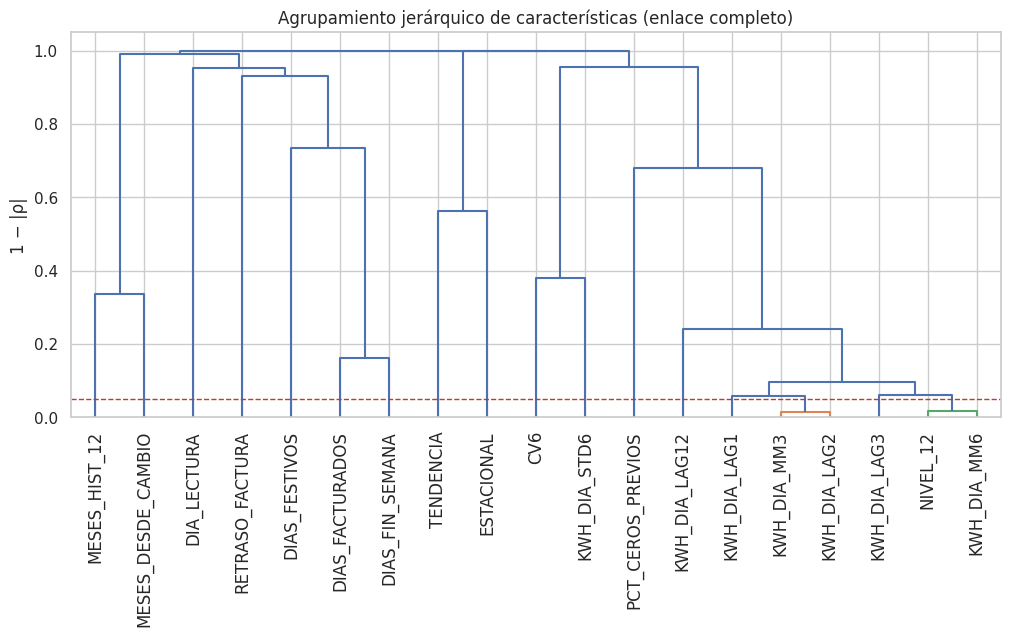

In [80]:
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, labels=candidatas, leaf_rotation=90, ax=ax, color_threshold=1 - UMBRAL_REDUNDANCIA)
ax.axhline(1 - UMBRAL_REDUNDANCIA, color='#C0392B', ls='--', lw=1)
ax.set_ylabel('1 − |ρ|'); ax.set_title('Agrupamiento jerárquico de características (enlace completo)')
guardar_figura(fig, '13_dendrograma_redundancia')
plt.show()

In [81]:
sensibilidad = {u: fcluster(Z, t=1 - u, criterion='distance').max() for u in [0.80, 0.85, 0.90, 0.95, 0.99]}
pd.Series(sensibilidad, name='variables resultantes').rename_axis('umbral |ρ|')

,variables resultantes
umbral |ρ|,
0.8000,13
0.8500,14
0.9000,14
0.9500,17
0.9900,19


In [82]:
seleccion_num = [c for c in candidatas if c in representantes]
print('Seleccionadas:', seleccion_num)

Seleccionadas: ['KWH_DIA_LAG1', 'KWH_DIA_LAG12', 'NIVEL_12', 'TENDENCIA', 'ESTACIONAL', 'CV6', 'KWH_DIA_STD6', 'KWH_DIA_MM3', 'KWH_DIA_LAG3', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS', 'DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA', 'MESES_DESDE_CAMBIO']


## 9. Conjunto final y exportación
Llaves, objetivo, línea base, categóricas y numéricas seleccionadas. Se guarda en Parquet, particionado por año.

In [83]:
cols_categoricas = ['ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES', 'MES_CONSUMO', 'COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA']
cols_categoricas += [c for c in ['UBICACION', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'CAMBIO_MEDIDOR'] if c in df.columns]
cols_finales = ['PERIODO', 'NIU_USUARIO', 'KWH_DIA', 'BENCH_KWH_DIA', 'PROM_SEM_BENCHMARK', 'BENCH_VALIDO'] \
               + cols_categoricas + seleccion_num
df = df[cols_finales]
pd.DataFrame({'columna': cols_finales})

,columna
0,PERIODO
1,NIU_USUARIO
2,KWH_DIA
3,BENCH_KWH_DIA
4,PROM_SEM_BENCHMARK
5,BENCH_VALIDO
6,ESTRATO_SECTOR
7,TIPO_MEDIDOR
8,MES
9,MES_CONSUMO


In [84]:
df['ANIO'] = dd.to_datetime(df['PERIODO']).dt.year
df.to_parquet(DRIVE_SALIDA, partition_on=['ANIO'], write_index=False, overwrite=True)
final = dd.read_parquet(DRIVE_SALIDA)
print(f'Registros: {len(final):,} | Columnas: {len(final.columns)}')

Registros: 97,636,686 | Columnas: 30


## 10. Conclusiones de la preparación
*(Se completa después de ejecutar el notebook, solo con los resultados medidos en las celdas anteriores.)*

### Supuestos no verificados con estos datos
1. La fecha real de lectura aproxima la fecha planeada del cronograma (sección 5).
2. El prefijo del hash de `NIU_USUARIO` produce una muestra pseudoaleatoria de usuarios (se contrasta solo por estrato, sección 1.1).
3. Las convenciones de umbrales (Tukey, Kuhn y Johnson, Cohen) son adecuadas para este problema; se reporta su sensibilidad.